# Introduction

This project compares four deep learning architectures (Custom CNN, ResNet18, DenseNet121, and DINOv3 ViT-S/16) for brain tumor MRI classification. Beyond comparing classification performance and model size, the experiments evaluate different training strategies, including training from scratch, pretrained feature extraction, and progressive partial fine-tuning (from the classification head to deeper layers, blocks). Additionally, confusion matrices and Grad-CAM are used to analyze classification errors and investigate model behavior across correct and incorrect predictions.

**Dataset:** Brain Tumor MRI Dataset by Masoud Nickparvar ([dataset](http://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)), containing four classes: glioma, meningioma, pituitary, and notumor. The dataset consists of 5,600 training images (split 80/20 for training and validation) and 1,600 test images.

**Training Note:** All checkpoints were trained during this project then downloaded and subsequently uploaded to Kaggle. Saved weights are reloaded for evaluation to avoid rerunning training and generating unnecessary outputs.

In [3]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import random
from torchvision import transforms
from torch.utils.data import Subset, DataLoader
from torchvision.datasets import ImageFolder
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import 
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from torchvision import models
from kaggle_secrets import UserSecretsClient
from transformers import AutoModel
import pandas as pd 
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from functools import partial
import warnings

In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


# Data preparation

In [6]:
TRAIN_DIR = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training'
TEST_DIR = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'

In [7]:
full_dataset = ImageFolder(TRAIN_DIR)

targets = np.array(full_dataset.targets)
indices = np.arange(len(full_dataset))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=targets
)

# Training Utilities

In [76]:
def freeze_bn_of_frozen_layers(model):
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            # Nếu parameter của BN đều đang frozen
            if not any(
                param.requires_grad
                for param in module.parameters()
            ):
                module.eval()

In [77]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    freeze_bn_of_frozen_layers(model)

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        
        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [78]:
def validate(
    model,
    val_loader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

# Plain Custom CNN

In [8]:
# Transform
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [9]:
train_full_dataset = ImageFolder(TRAIN_DIR, transform=train_transform)
val_full_dataset = ImageFolder(TRAIN_DIR, transform=val_transform)

test_dataset = ImageFolder(TEST_DIR,transform=test_transform)
train_dataset = Subset(train_full_dataset, train_indices)
val_dataset = Subset(val_full_dataset, val_indices)


In [10]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [11]:
class CustomCNN(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(

            # Convolution Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32, 
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Convolution Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Convolution Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)

        return x

In [12]:
custom_cnn = CustomCNN(num_classes=4)
custom_cnn = custom_cnn.to(device)

In [13]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    custom_cnn.parameters(),
    lr=0.001
)

In [ ]:
best_val_acc = 0.0
patience = 10
epochs_without_improvement = 0
num_epochs = 100

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        custom_cnn,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        custom_cnn,
        val_loader,
        criterion,
        device
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            custom_cnn.state_dict(),
            "/kaggle/working/custom_cnn.pth"
        )

        print("Saved best model")

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

In [ ]:
custom_cnn = CustomCNN(num_classes=4).to(device)

custom_cnn.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/custom-cnn/pytorch/default/1/best_custom_cnn.pth",
        map_location=device
    )
)

custom_cnn.eval()

In [79]:
# Custom CNN evaluation in test loader

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = custom_cnn(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(
            labels.cpu().numpy()
        )

        y_pred.extend(
            predictions.cpu().numpy()
        )

test_accuracy = accuracy_score(y_true, y_pred)

print("Final Test Evaluation - Custom CNN")

print(f"Test Accuracy: {test_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=test_dataset.classes
    )
)

Final Test Evaluation - Custom CNN
Test Accuracy: 0.8144
              precision    recall  f1-score   support

      glioma       0.90      0.66      0.76       400
  meningioma       0.79      0.62      0.70       400
     notumor       0.75      0.99      0.85       400
   pituitary       0.85      0.98      0.91       400

    accuracy                           0.81      1600
   macro avg       0.82      0.81      0.81      1600
weighted avg       0.82      0.81      0.81      1600



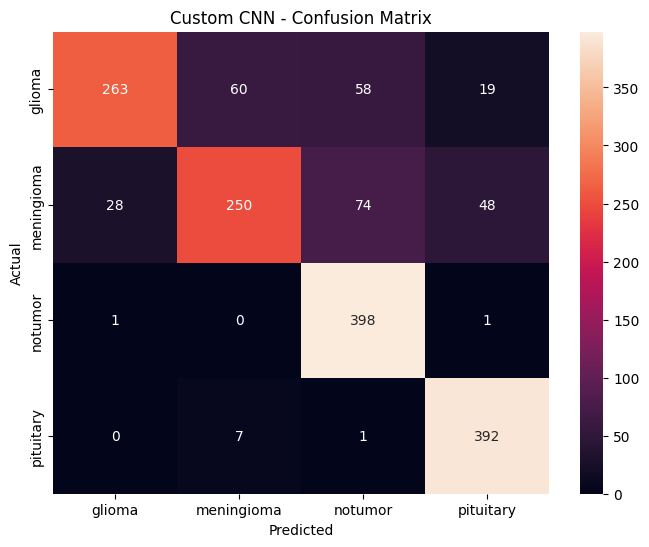

In [17]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Custom CNN - Confusion Matrix")

plt.show()

The Custom CNN struggles to distinguish between tumor classes, particularly glioma and meningioma, with only 263 and 250 out of 400 images correctly classified, respectively. Notably, 133 tumor images were incorrectly predicted as "notumor", highlighting a significant risk of missed tumor detection. In contrast, the model correctly classified 398 out of 400 tumor-free images, suggesting that detecting the presence of a tumor is more challenging than recognizing tumor-free images.

# ResNet-18

In [19]:
train_transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [20]:
train_full_resnet = ImageFolder(
    TRAIN_DIR,
    transform=train_transform_resnet
)

val_full_resnet = ImageFolder(
    TRAIN_DIR,
    transform=val_transform_resnet
)

test_dataset_resnet = ImageFolder(
    TEST_DIR,
    transform=test_transform_resnet
)

train_dataset_resnet = Subset(
    train_full_resnet,
    train_indices
)

val_dataset_resnet = Subset(
    val_full_resnet,
    val_indices
)

In [21]:
train_loader_resnet = DataLoader(
    train_dataset_resnet,
    batch_size=32,
    shuffle=True
)

val_loader_resnet = DataLoader(
    val_dataset_resnet,
    batch_size=32,
    shuffle=False
)

test_loader_resnet = DataLoader(
    test_dataset_resnet,
    batch_size=32,
    shuffle=False
)

In [22]:
resnet = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Phase 1: Feature Extraction - Freeze backbone, train only the fc layer (classification head)
resnet.fc = nn.Linear(
    resnet.fc.in_features,
    4
)

resnet = resnet.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s] 


### Phase 1 

In [ ]:
for param in resnet.parameters():
    # print("layers: \n", param)
    param.requires_grad = False

for param in resnet.fc.parameters():
    # print("fc layer: \n", param)
    param.requires_grad = True

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    resnet.fc.parameters(),
    lr=1e-3
)

In [ ]:
best_val_acc = 0.0
patience = 10
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        resnet,
        train_loader_resnet,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        resnet,
        val_loader_resnet,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            resnet.state_dict(),
            "/kaggle/working/best_resnet18_head.pth"
        )

        print("Saved best model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

In [25]:
# Phase 1 evalutaion with validation loader
resnet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_head.pth",
        map_location=device
    )
)

resnet.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_resnet:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_resnet.classes
    )
)

Validation Accuracy: 0.8938
              precision    recall  f1-score   support

      glioma       0.92      0.92      0.92       280
  meningioma       0.81      0.82      0.81       280
     notumor       0.94      0.95      0.94       280
   pituitary       0.90      0.89      0.89       280

    accuracy                           0.89      1120
   macro avg       0.89      0.89      0.89      1120
weighted avg       0.89      0.89      0.89      1120



### Phase 2

In [26]:
resnet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_head.pth",
        map_location=device
    )
)

<All keys matched successfully>

In [ ]:
# unfreeze layer 4
for param in resnet.layer4.parameters(): 
    param.requires_grad = True

In [ ]:
optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet.parameters()
    ),
    lr=1e-4
)

In [ ]:
best_val_acc = 0.8938   # best Phase 1
patience = 10
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        resnet,
        train_loader_resnet,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        resnet,
        val_loader_resnet,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            resnet.state_dict(),
            "/kaggle/working/best_resnet18_layer4.pth"
        )

        print("Saved best Phase 2 model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

In [27]:
# Phase 2 evalutaion with validation loader
resnet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_layer4.pth",
        map_location=device
    )
)

resnet.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_resnet:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_resnet.classes
    )
)

Validation Accuracy: 0.8955
              precision    recall  f1-score   support

      glioma       0.90      0.92      0.91       280
  meningioma       0.85      0.78      0.81       280
     notumor       0.94      0.95      0.94       280
   pituitary       0.88      0.94      0.91       280

    accuracy                           0.90      1120
   macro avg       0.89      0.90      0.89      1120
weighted avg       0.89      0.90      0.89      1120



### Phase 3

In [28]:
resnet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_layer4.pth",
        map_location=device
    )
)

# unfreeze layer 3
for param in resnet.layer3.parameters(): 
    param.requires_grad = True

optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet.parameters()
    ),
    lr=1e-5
)

In [ ]:
best_val_acc = 0.8955   # best Phase 2
patience = 10
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        resnet,
        train_loader_resnet,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        resnet,
        val_loader_resnet,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            resnet.state_dict(),
            "/kaggle/working/best_resnet18_layer3.pth"
        )

        print("Saved best Phase 3 model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

In [29]:
# Phase 3 evalutaion with validation loader
resnet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_layer3.pth",
        map_location=device
    )
)

resnet.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_resnet:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_resnet.classes
    )
)

Validation Accuracy: 0.9786
              precision    recall  f1-score   support

      glioma       1.00      0.99      0.99       280
  meningioma       0.96      0.96      0.96       280
     notumor       0.99      0.99      0.99       280
   pituitary       0.97      0.99      0.98       280

    accuracy                           0.98      1120
   macro avg       0.98      0.98      0.98      1120
weighted avg       0.98      0.98      0.98      1120



In [46]:
# ResNet-18 best checkpoint evaluation in test loader
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader_resnet:
        images = images.to(device)
        outputs = resnet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(y_true, y_pred)

print("Final Test Evaluation - ResNet18 (Best Phase 3 Checkpoint: Layer3 & Layer4 Fine-Tuned)")

print(f"Test Accuracy: {test_accuracy:.4f}")

print(classification_report(y_true, y_pred, target_names=test_dataset_resnet.classes))

Final Test Evaluation - ResNet18 (Best Phase 3 Checkpoint: Layer3 & Layer4 Fine-Tuned)
Test Accuracy: 0.9431
              precision    recall  f1-score   support

      glioma       0.99      0.81      0.89       400
  meningioma       0.89      0.96      0.93       400
     notumor       0.94      1.00      0.97       400
   pituitary       0.97      0.99      0.98       400

    accuracy                           0.94      1600
   macro avg       0.95      0.94      0.94      1600
weighted avg       0.95      0.94      0.94      1600



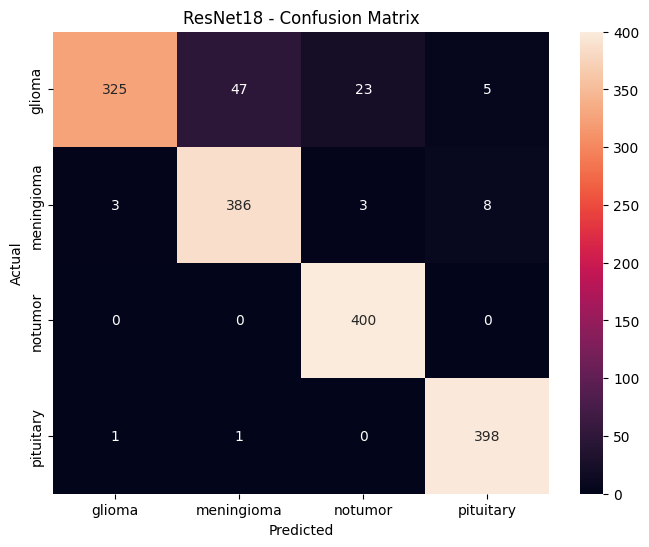

In [34]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet18 - Confusion Matrix")

plt.show()

Glioma is the most challenging class, with 47 samples misclassified as meningioma and 23 as notumor. This suggests that the model has difficulty distinguishing certain glioma images from these two classes. Remarkably, all 400 tumor-free images were correctly classified, with none misclassified as containing tumors. However, 26 images containing tumors were incorrectly predicted as "notumor", highlighting the remaining risk of missed tumor detection.

# DenseNet-121

In [36]:
train_transform_densenet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform_densenet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform_densenet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [37]:
train_full_densenet = ImageFolder(
    TRAIN_DIR,
    transform=train_transform_densenet
)

val_full_densenet = ImageFolder(
    TRAIN_DIR,
    transform=val_transform_densenet
)

test_dataset_densenet = ImageFolder(
    TEST_DIR,
    transform=test_transform_densenet
)

train_dataset_densenet = Subset(
    train_full_densenet,
    train_indices
)

val_dataset_densenet = Subset(
    val_full_densenet,
    val_indices
)

In [39]:
train_loader_densenet = DataLoader(
    train_dataset_densenet,
    batch_size=32,
    shuffle=True
)

val_loader_densenet = DataLoader(
    val_dataset_densenet,
    batch_size=32,
    shuffle=False
)

test_loader_densenet = DataLoader(
    test_dataset_densenet,
    batch_size=32,
    shuffle=False
)

In [41]:
densenet = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

densenet.classifier = nn.Linear(
    densenet.classifier.in_features,
    4
)

densenet = densenet.to(device)

### Phase 1

In [ ]:
for param in densenet.parameters():
    param.requires_grad = False

for param in densenet.classifier.parameters():
    param.requires_grad = True

densenet = densenet.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    densenet.classifier.parameters(),
    lr=1e-3
)

In [ ]:
best_val_acc = 0.0
patience = 10
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        densenet,
        train_loader_densenet,
        criterion,
        optimizer,
        device,
    )

    val_loss, val_acc = validate(
        densenet,
        val_loader_densenet,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            densenet.state_dict(),
            "/kaggle/working/best_densenet121_head.pth"
        )

        print("Saved best model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

In [42]:
# Phase 1 evalutaion with validation loader
densenet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_head.pth",
        map_location=device
    )
)

densenet.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_densenet:
        images = images.to(device)
        labels = labels.to(device)

        outputs = densenet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_densenet.classes
    )
)

Validation Accuracy: 0.9205
              precision    recall  f1-score   support

      glioma       0.97      0.87      0.92       280
  meningioma       0.82      0.90      0.86       280
     notumor       0.96      0.97      0.97       280
   pituitary       0.94      0.94      0.94       280

    accuracy                           0.92      1120
   macro avg       0.92      0.92      0.92      1120
weighted avg       0.92      0.92      0.92      1120



### Phase 2

In [ ]:
densenet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_head.pth",
        map_location=device,
        weights_only=True
    )
)

In [ ]:
for param in densenet.features.denseblock4.parameters():
    param.requires_grad = True

for param in densenet.features.norm5.parameters():
    param.requires_grad = True

In [ ]:
optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        densenet.parameters()
    ),
    lr=1e-4
)

In [ ]:
best_val_acc = 0.9205   # best Phase 1
patience = 10
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        densenet,
        train_loader_densenet,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        densenet,
        val_loader_densenet,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            densenet.state_dict(),
            "/kaggle/working/best_densenet121_denseblock4.pth"
        )

        print("Saved best Phase 2 model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

In [44]:
# Phase 2 evalutaion with validation loader
densenet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_denseblock4.pth",
        map_location=device
    )
)

densenet.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_densenet:
        images = images.to(device)
        labels = labels.to(device)

        outputs = densenet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_densenet.classes
    )
)

Validation Accuracy: 0.9795
              precision    recall  f1-score   support

      glioma       0.99      0.98      0.98       280
  meningioma       0.95      0.97      0.96       280
     notumor       0.99      0.98      0.98       280
   pituitary       0.99      0.99      0.99       280

    accuracy                           0.98      1120
   macro avg       0.98      0.98      0.98      1120
weighted avg       0.98      0.98      0.98      1120



### Phase 3

In [40]:
densenet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_denseblock4.pth",
        map_location=device,
        weights_only=True
    )
)

densenet = densenet.to(device)

In [ ]:
# Freeze all parameters
for param in densenet.parameters():
    param.requires_grad = False

# Unfreeze DenseBlock3
for param in densenet.features.denseblock3.parameters():
    param.requires_grad = True

# Unfreeze Transition3
for param in densenet.features.transition3.parameters():
    param.requires_grad = True

# Unfreeze DenseBlock4
for param in densenet.features.denseblock4.parameters():
    param.requires_grad = True

# Unfreeze norm5
for param in densenet.features.norm5.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in densenet.classifier.parameters():
    param.requires_grad = True

In [ ]:
optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        densenet.parameters()
    ),
    lr=1e-5
)

In [ ]:
best_val_acc = 0.9795   # best Phase 2
patience = 10
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        densenet,
        train_loader_densenet,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        densenet,
        val_loader_densenet,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            densenet.state_dict(),
            "/kaggle/working/best_densenet121_denseblock3.pth"
        )

        print("Saved best Phase 3 model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

In [49]:
# Phase 3 evalutaion with validation loader
densenet.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_denseblock3.pth",
        map_location=device
    )
)

densenet.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_densenet:
        images = images.to(device)
        labels = labels.to(device)

        outputs = densenet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_densenet.classes
    )
)

Validation Accuracy: 0.9866
              precision    recall  f1-score   support

      glioma       0.99      0.99      0.99       280
  meningioma       0.97      0.97      0.97       280
     notumor       0.99      0.99      0.99       280
   pituitary       0.99      1.00      0.99       280

    accuracy                           0.99      1120
   macro avg       0.99      0.99      0.99      1120
weighted avg       0.99      0.99      0.99      1120



In [73]:
# DenseNet-121 best checkpoint evaluation in test loader
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader_densenet:
        images = images.to(device)
        labels = labels.to(device)

        outputs = densenet(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(y_true, y_pred)

print("Final Test Evaluation - DenseNet121 (Best Phase 3 Checkpoint: Dense block 3 & 4 Fine-Tuned)")

print(f"Test Accuracy: {test_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=test_dataset_densenet.classes
    )
)

Final Test Evaluation - DenseNet121 (Best Phase 3 Checkpoint: Dense block 3 & 4 Fine-Tuned)
Test Accuracy: 0.9444
              precision    recall  f1-score   support

      glioma       0.99      0.81      0.89       400
  meningioma       0.91      0.97      0.94       400
     notumor       0.91      1.00      0.95       400
   pituitary       0.99      1.00      0.99       400

    accuracy                           0.94      1600
   macro avg       0.95      0.94      0.94      1600
weighted avg       0.95      0.94      0.94      1600



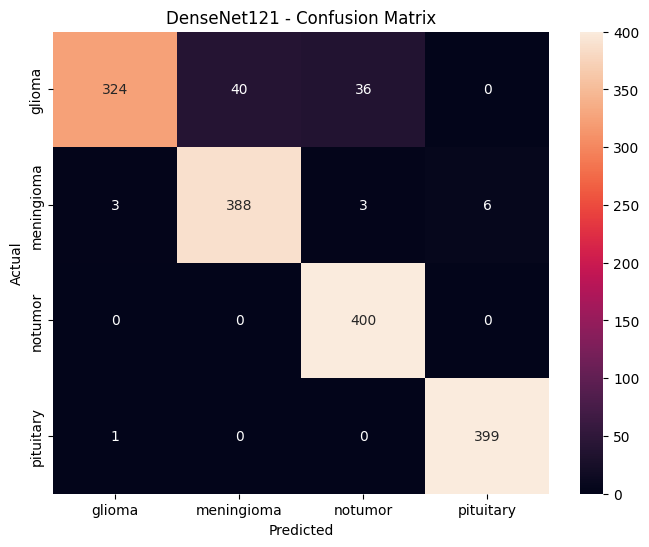

In [51]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DenseNet121 - Confusion Matrix")

plt.show()

Glioma remains the most challenging class for DenseNet121, with 40 glioma images misclassified as meningioma and 36 as notumor. Although the model correctly classified all 400 tumor-free images, 39 images containing tumors were incorrectly predicted as notumor

# DINOv3 ViT-S/16

In [57]:
HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")

MODEL_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"

In [81]:
backbone = AutoModel.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN
).to(device)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

In [68]:
val_full_dinov3 = val_full_densenet
test_dataset_dinov3 = test_dataset_densenet
train_loader_dinov3 = train_loader_densenet
val_loader_dinov3 = val_loader_densenet
test_loader_dinov3 = test_loader_densenet

In [59]:
class DINOv3Classifier(nn.Module):

    def __init__(self, backbone, num_classes=4):
        super().__init__()

        self.backbone = backbone

        self.classifier = nn.Linear(
            backbone.config.hidden_size,
            num_classes
        )

    def forward(self, x):

        outputs = self.backbone(pixel_values=x)

        cls_token = outputs.last_hidden_state[:, 0, :]

        logits = self.classifier(cls_token)

        return logits

    def train(self, mode=True):
        super().train(mode)

        # Giữ backbone ở eval mode khi toàn bộ weights bị frozen
        if mode and not any(
            p.requires_grad for p in self.backbone.parameters()
        ):
            self.backbone.eval()

        return self

In [61]:
dinov3 = DINOv3Classifier(
    backbone=backbone,
    num_classes=4
).to(device)

### Phase 1

In [ ]:
# Freeze backbone
for param in dinov3.backbone.parameters():
    param.requires_grad = False

# Train classifier
for param in dinov3.classifier.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    dinov3.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [ ]:
best_val_acc = 0.0
patience = 10
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        dinov3,
        train_loader_dinov3,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        dinov3,
        val_loader_dinov3,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            dinov3.state_dict(),
            "/kaggle/working/best_dinov3_head.pth"
        )

        print("Saved best DINOv3 Phase 1 model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

print(f"\nBest Val Accuracy: {best_val_acc:.4f}")

In [62]:
# Phase 1 evalutaion with validation loader
dinov3.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_head.pth",
        map_location=device
    )
)

dinov3.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_dinov3:
        images = images.to(device)
        labels = labels.to(device)

        outputs = dinov3(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_dinov3.classes
    )
)

Validation Accuracy: 0.9223
              precision    recall  f1-score   support

      glioma       0.95      0.89      0.92       280
  meningioma       0.85      0.88      0.87       280
     notumor       0.95      0.97      0.96       280
   pituitary       0.93      0.95      0.94       280

    accuracy                           0.92      1120
   macro avg       0.92      0.92      0.92      1120
weighted avg       0.92      0.92      0.92      1120



### Phase 2

In [ ]:
phase1_path = "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_head.pth"

dinov3.load_state_dict(
    torch.load(
        phase1_path,
        map_location=device,
        weights_only=True
    )
)

dinov3 = dinov3.to(device)


In [ ]:
# Freeze backbone
for param in dinov3.backbone.parameters():
    param.requires_grad = False

# Unfreeze 2 last Transformer blocks
for param in dinov3.backbone.layer[-2:].parameters():
    param.requires_grad = True

# Unfreeze final LayerNorm
for param in dinov3.backbone.norm.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in dinov3.classifier.parameters():
    param.requires_grad = True

In [ ]:
optimizer = torch.optim.AdamW(
    [
        {
            "params": dinov3.backbone.layer[-2:].parameters(),
            "lr": 1e-5
        },
        {
            "params": dinov3.backbone.norm.parameters(),
            "lr": 1e-5
        },
        {
            "params": dinov3.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

In [ ]:
best_val_acc = 0.9223

max_epochs = 30
patience = 10
epochs_without_improvement = 0

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        dinov3,
        train_loader_dinov3,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        dinov3,
        val_loader_dinov3,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            dinov3.state_dict(),
            "/kaggle/working/best_dinov3_last2blocks.pth"
        )

        print("Saved best DINOv3 Phase 2 model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

print(f"\nBest Phase 2 Val Accuracy: {best_val_acc:.4f}")

In [63]:
# Phase 2 evalutaion with validation loader
dinov3.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_last2blocks.pth",
        map_location=device
    )
)

dinov3.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_dinov3:
        images = images.to(device)
        labels = labels.to(device)

        outputs = dinov3(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_dinov3.classes
    )
)

Validation Accuracy: 0.9768
              precision    recall  f1-score   support

      glioma       0.98      0.98      0.98       280
  meningioma       0.97      0.95      0.96       280
     notumor       0.99      0.99      0.99       280
   pituitary       0.97      0.99      0.98       280

    accuracy                           0.98      1120
   macro avg       0.98      0.98      0.98      1120
weighted avg       0.98      0.98      0.98      1120



### Phase 3

In [ ]:
# Load best Phase 2
dinov3.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_last2blocks.pth",
        map_location=device,
        weights_only=True
    )
)

In [ ]:
# Freeze backbone
for param in dinov3.backbone.parameters():
    param.requires_grad = False

# Unfreeze last 4 Transformer blocks
for param in dinov3.backbone.layer[-4:].parameters():
    param.requires_grad = True

# Unfreeze final LayerNorm
for param in dinov3.backbone.norm.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in dinov3.classifier.parameters():
    param.requires_grad = True

In [51]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [
        {
            "params": dinov3.backbone.layer[8:10].parameters(),
            "lr": 3e-6
        },
        {
            "params": dinov3.backbone.layer[10:12].parameters(),
            "lr": 5e-6
        },
        {
            "params": dinov3.backbone.norm.parameters(),
            "lr": 5e-6
        },
        {
            "params": dinov3.classifier.parameters(),
            "lr": 3e-5
        }
    ],
    weight_decay=1e-4
)

In [ ]:
best_val_acc = 0.9768

max_epochs = 30
patience = 10
epochs_without_improvement = 0

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        dinov3,
        train_loader_dinov3,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        dinov3,
        val_loader_dinov3,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            dinov3.state_dict(),
            "/kaggle/working/best_dinov3_last4blocks.pth"
        )

        print("Saved best DINOv3 Phase 3 model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

print(f"\nBest Phase 3 Val Accuracy: {best_val_acc:.4f}")

In [82]:
# Phase 3 evalutaion with validation loader
dinov3.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_last4blocks.pth",
        map_location=device
    )
)

dinov3.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader_dinov3:
        images = images.to(device)
        labels = labels.to(device)

        outputs = dinov3(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {val_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=val_full_dinov3.classes
    )
)

Validation Accuracy: 0.9866
              precision    recall  f1-score   support

      glioma       0.99      0.98      0.98       280
  meningioma       0.98      0.98      0.98       280
     notumor       1.00      0.99      1.00       280
   pituitary       0.98      0.99      0.99       280

    accuracy                           0.99      1120
   macro avg       0.99      0.99      0.99      1120
weighted avg       0.99      0.99      0.99      1120



In [74]:
# DINOv3 ViT-S/16 best checkpoint evaluation in test loader
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader_dinov3:
        images = images.to(device)
        labels = labels.to(device)

        outputs = dinov3(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(y_true, y_pred)

print("Final Test Evaluation - DINOv3 ViT-S/16 (Best Phase 3 Checkpoint: Last 4 blocks Fine-Tuned)")

print(f"Test Accuracy: {test_accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=test_dataset_dinov3.classes
    )
)

Final Test Evaluation - DINOv3 ViT-S/16 (Best Phase 3 Checkpoint: Last 4 blocks Fine-Tuned)
Test Accuracy: 0.9506
              precision    recall  f1-score   support

      glioma       1.00      0.81      0.90       400
  meningioma       0.87      0.99      0.93       400
     notumor       0.96      1.00      0.98       400
   pituitary       0.99      1.00      1.00       400

    accuracy                           0.95      1600
   macro avg       0.96      0.95      0.95      1600
weighted avg       0.96      0.95      0.95      1600



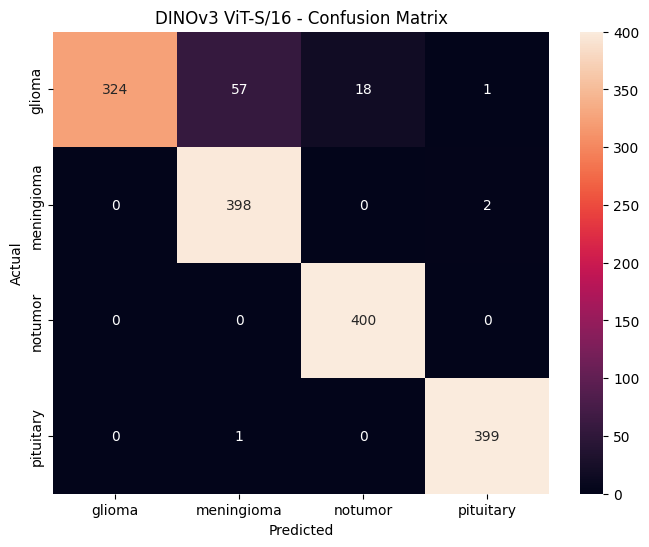

In [75]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DINOv3 ViT-S/16 - Confusion Matrix")

plt.show()

DINOv3 ViT-S/16 reduces the number of tumor images misclassified as "notumor" to 18, compared with 26 for ResNet18 and 39 for DenseNet121. However, glioma remains the most challenging class, with 57 images misclassified as meningioma, the highest among the three pretrained models. This suggests that DINOv3 performs better at avoiding missed tumor detections but still struggles to distinguish glioma from meningioma.

### Adjust learning rate in phase 3

In [53]:
dinov3.load_state_dict(
    torch.load(
        "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_last4blocks.pth",
        map_location=device,
        weights_only=True
    )
)

<All keys matched successfully>

In [54]:
# Freeze backbone
for param in dinov3.backbone.parameters():
    param.requires_grad = False

# Unfreeze last 4 Transformer blocks
for param in dinov3.backbone.layer[-4:].parameters():
    param.requires_grad = True

# Unfreeze final LayerNorm
for param in dinov3.backbone.norm.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in dinov3.classifier.parameters():
    param.requires_grad = True

In [55]:
# adjust learning rate
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [
        {
            "params": dinov3.backbone.layer[8:10].parameters(),
            "lr": 1e-6
        },
        {
            "params": dinov3.backbone.layer[10:12].parameters(),
            "lr": 2e-6
        },
        {
            "params": dinov3.backbone.norm.parameters(),
            "lr": 2e-6
        },
        {
            "params": dinov3.classifier.parameters(),
            "lr": 2e-5
        }
    ],
    weight_decay=1e-4
)

In [56]:
best_val_acc = 0.9866

max_epochs = 30
patience = 10
epochs_without_improvement = 0

for epoch in range(max_epochs):

    train_loss, train_acc = train_one_epoch(
        dinov3,
        train_loader_dinov3,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        dinov3,
        val_loader_dinov3,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save(
            dinov3.state_dict(),
            "/kaggle/working/best_dinov3_last4blocks_lowLR.pth"
        )

        print("Saved best DINOv3 Phase 3 with low LR model")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

print(f"\nBest Phase 3 Val Accuracy: {best_val_acc:.4f}")

Epoch 1/30 | Train Loss: 0.0082 | Train Acc: 0.9980 | Val Loss: 0.0487 | Val Acc: 0.9839
Epoch 2/30 | Train Loss: 0.0088 | Train Acc: 0.9978 | Val Loss: 0.0488 | Val Acc: 0.9830
Epoch 3/30 | Train Loss: 0.0083 | Train Acc: 0.9973 | Val Loss: 0.0476 | Val Acc: 0.9839
Epoch 4/30 | Train Loss: 0.0080 | Train Acc: 0.9978 | Val Loss: 0.0481 | Val Acc: 0.9848
Epoch 5/30 | Train Loss: 0.0076 | Train Acc: 0.9982 | Val Loss: 0.0460 | Val Acc: 0.9839
Epoch 6/30 | Train Loss: 0.0070 | Train Acc: 0.9980 | Val Loss: 0.0459 | Val Acc: 0.9857
Epoch 7/30 | Train Loss: 0.0060 | Train Acc: 0.9989 | Val Loss: 0.0460 | Val Acc: 0.9830
Epoch 8/30 | Train Loss: 0.0074 | Train Acc: 0.9973 | Val Loss: 0.0457 | Val Acc: 0.9848
Epoch 9/30 | Train Loss: 0.0072 | Train Acc: 0.9982 | Val Loss: 0.0464 | Val Acc: 0.9857
Epoch 10/30 | Train Loss: 0.0064 | Train Acc: 0.9987 | Val Loss: 0.0467 | Val Acc: 0.9857
Early stopping

Best Phase 3 Val Accuracy: 0.9866


Adjusting the learning rate in Phase 3 did not improve the model's performance, and training was stopped early after 10 epochs due to a lack of improvement in validation performance.

# Model Interpretability with Grad-CAM

In [77]:
def reshape_transform_dino(tensor, height, width, num_register_tokens):
    # tensor: [B, N, C]

    num_prefix_tokens = 1 + num_register_tokens

    # Remove CLS token and register tokens
    patch_tokens = tensor[:, num_prefix_tokens:, :]

    assert patch_tokens.shape[1] == height * width, (
        f"Expected {height * width} patch tokens, "
        f"got {patch_tokens.shape[1]}"
    )

    # [B, 196, 384] -> [B, 14, 14, 384]
    patch_tokens = patch_tokens.reshape(
        tensor.shape[0], height, width, tensor.shape[-1]
    )

    # [B, 14, 14, 384] -> [B, 384, 14, 14]
    return patch_tokens.permute(0, 3, 1, 2).contiguous()

In [79]:
patch_size = dinov3.backbone.config.patch_size
num_register_tokens = dinov3.backbone.config.num_register_tokens

if isinstance(patch_size, (tuple, list)):
    patch_h, patch_w = patch_size
else:
    patch_h = patch_w = patch_size

image, _ = test_loader_dinov3.dataset[0]
height = image.shape[-2] // patch_h
width = image.shape[-1] // patch_w

reshape_dino = partial(
    reshape_transform_dino,
    height=height,
    width=width,
    num_register_tokens=num_register_tokens
)

In [68]:
def get_gradcam_result(
    model, target_layer, dataset, idx, device,
    reshape_transform=None,
    mean=None,
    std=None
):
    model = model.to(device).eval()

    image, true_label = dataset[idx]
    input_tensor = image.unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)
        pred_label = probs.argmax(dim=1).item()
        confidence = probs[0, pred_label].item()

    # Generate Grad-CAM
    with torch.enable_grad():
        with GradCAM(
            model=model,
            target_layers=[target_layer],
            reshape_transform=reshape_transform
        ) as cam:
            grayscale_cam = cam(
                input_tensor=input_tensor,
                targets=[ClassifierOutputTarget(pred_label)]
            )[0]

    # Original MRI
    rgb_image = image.permute(1, 2, 0).cpu().numpy()

    if mean is not None and std is not None:
        rgb_image = (
            rgb_image * np.array(std)
            + np.array(mean)
        )

    rgb_image = np.clip(rgb_image, 0, 1).astype(np.float32)

    overlay = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    return {
        "image": rgb_image,
        "heatmap": grayscale_cam,
        "overlay": overlay,
        "true": dataset.classes[true_label],
        "pred": dataset.classes[pred_label],
        "pred_idx": pred_label,
        "confidence": confidence
    }

In [54]:
# config for grad-cam
best_weight_path = {
    'custom_cnn': "/kaggle/input/models/onphct/custom-cnn/pytorch/default/1/best_custom_cnn.pth",
    'resnet': "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_layer3.pth",
    'densenet': "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_denseblock3.pth",
    'dinov3': "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_last4blocks.pth"
}

checkpoint = {
    'customcnn_cp': torch.load(
        best_weight_path['custom_cnn'],
        map_location=device,
        weights_only=True
    ),
    
    'resnet_cp': torch.load(
        best_weight_path['resnet'],
        map_location=device,
        weights_only=True
    ),

    'densenet_cp': torch.load(
        best_weight_path['densenet'],
        map_location=device,
        weights_only=True
    ),

    'dinov3_cp': torch.load(
        best_weight_path['dinov3'],
        map_location=device,
        weights_only=True
    )
}

## Cross-Architecture Grad-CAM Comparison

In [80]:
def compare_gradcam(idx):

    # Custom CNN
    custom_cnn.load_state_dict(checkpoint['customcnn_cp'])

    cnn_result = get_gradcam_result(
        model=custom_cnn,
        target_layer=custom_cnn.features[7],
        dataset=test_loader.dataset,
        idx=idx,
        device=device
    )

    # ResNet18
    resnet.load_state_dict(checkpoint['resnet_cp'])

    resnet_result = get_gradcam_result(
        model=resnet,
        target_layer=resnet.layer4[-1],
        dataset=test_loader_resnet.dataset,
        idx=idx,
        device=device,
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

    # DenseNet121
    densenet.load_state_dict(checkpoint['densenet_cp'])

    densenet_result = get_gradcam_result(
        model=densenet,
        target_layer=densenet.features.denseblock4,
        dataset=test_loader_densenet.dataset,
        idx=idx,
        device=device,
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

    # DINOv3
    dinov3.load_state_dict(checkpoint['dinov3_cp'])

    dino_result = get_gradcam_result(
        model=dinov3,
        target_layer=dinov3.backbone.layer[-1].norm1,
        dataset=test_loader_dinov3.dataset,
        idx=idx,
        device=device,
        reshape_transform=reshape_dino,
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

    results = [
        cnn_result,
        resnet_result,
        densenet_result,
        dino_result
    ]

    names = [
        "Custom CNN",
        "ResNet18",
        "DenseNet121",
        "DINOv3"
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    axes[0].imshow(cnn_result["image"])
    axes[0].set_title(
        f"Original MRI\nTrue: {cnn_result['true']}"
    )

    for i, (name, result) in enumerate(zip(names, results), start=1):
        axes[i].imshow(result["overlay"])
        axes[i].set_title(
            f"{name}\n"
            f"Pred: {result['pred']} ({result['confidence']:.2%})"
        )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

glioma - idx: 327


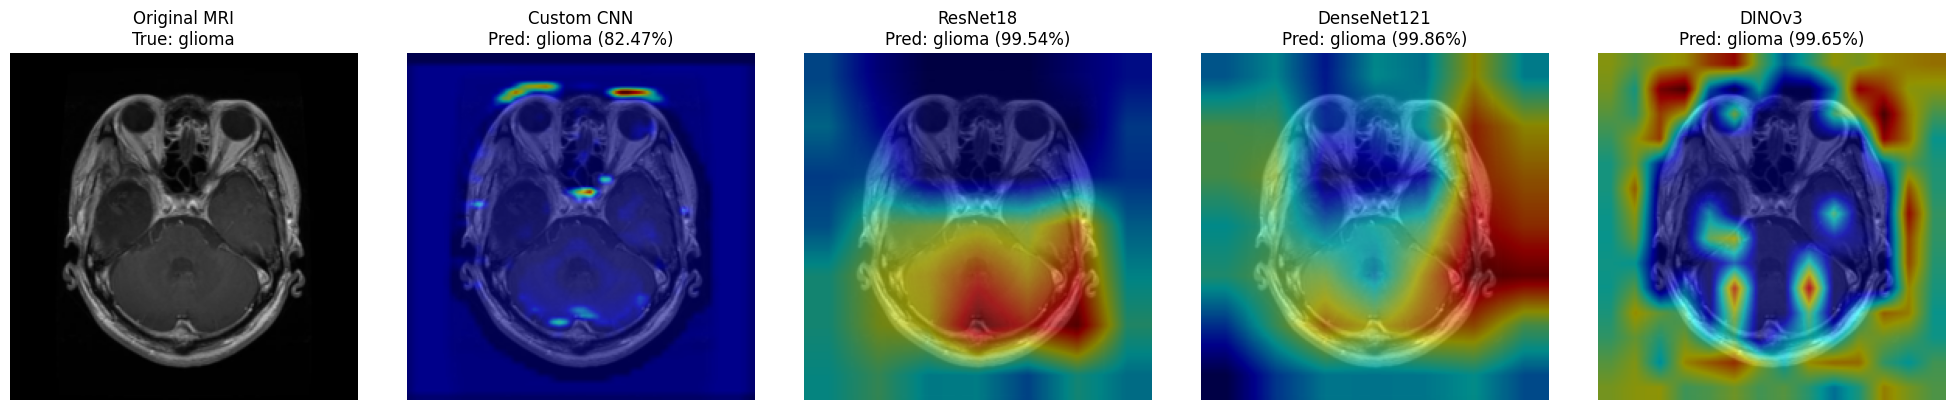

meningioma - idx: 457


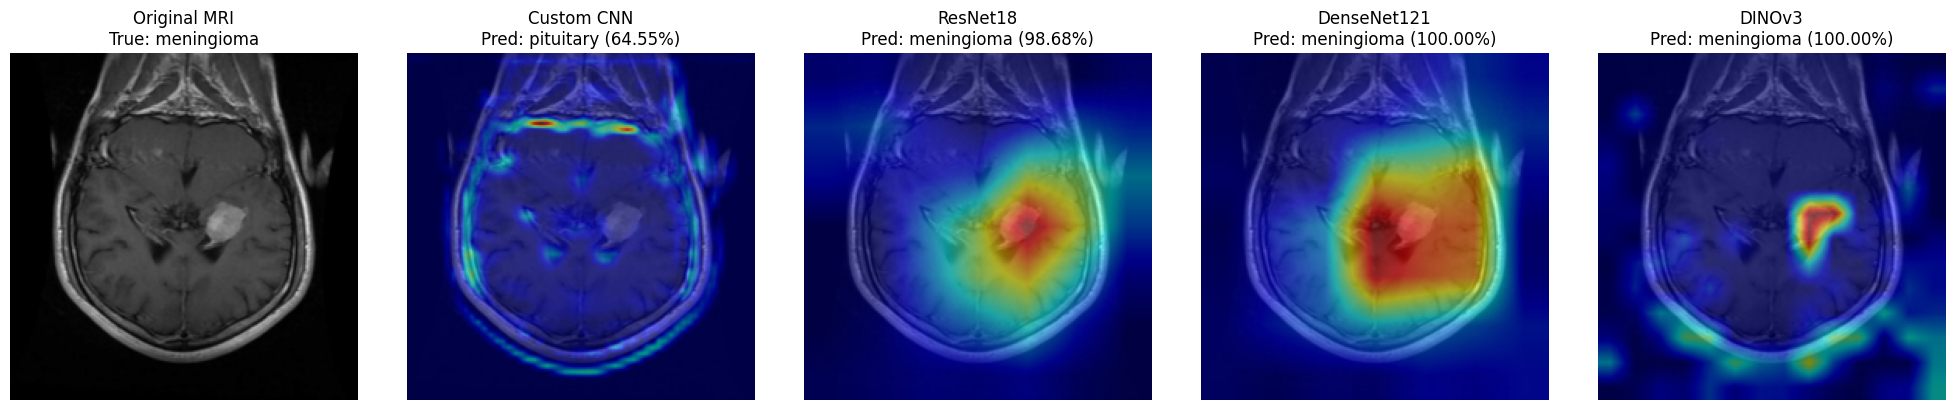

notumor - idx: 812


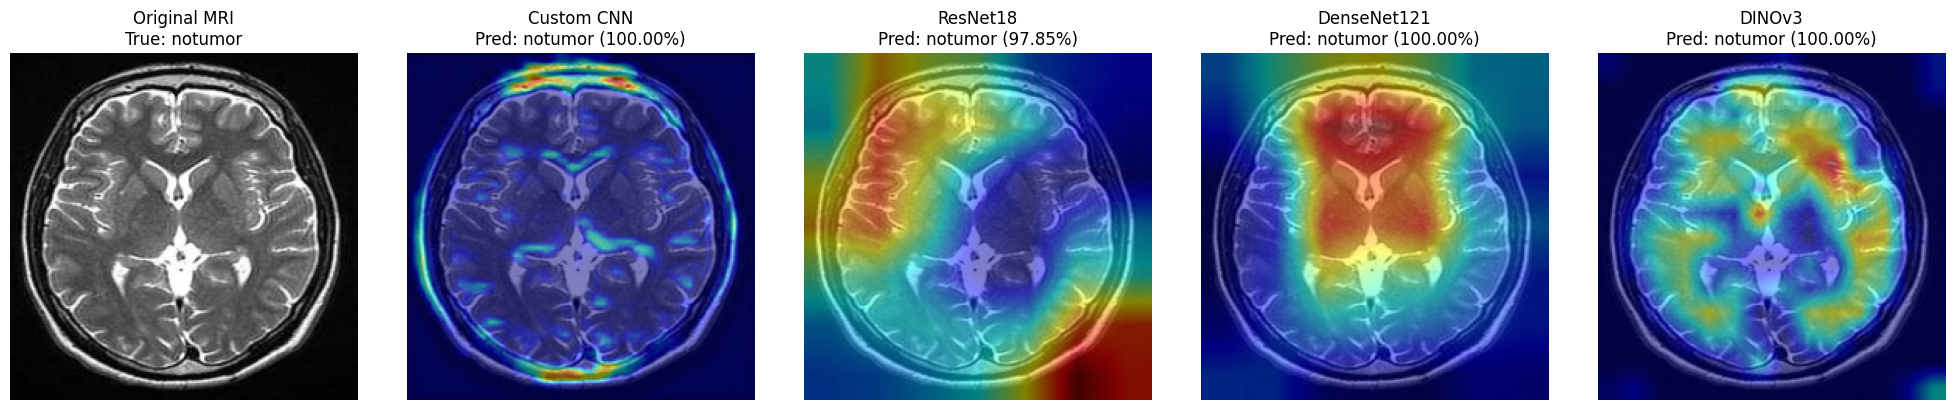

pituitary - idx: 1579


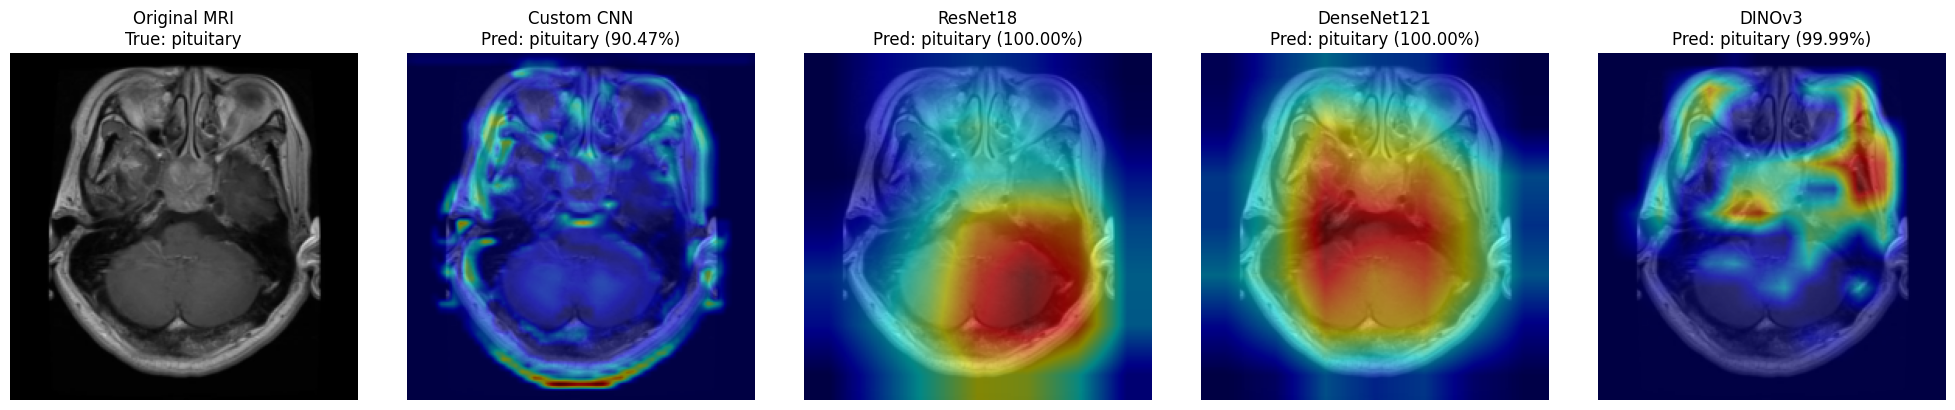

In [88]:
random.seed(42)

dataset = test_loader.dataset

for class_idx, class_name in enumerate(dataset.classes):

    indices = [
        idx
        for idx, (_, label) in enumerate(dataset.samples)
        if label == class_idx
    ]

    selected_idx = random.choice(indices)

    print(f"{class_name} - idx: {selected_idx}")

    compare_gradcam(idx=selected_idx)

## Correct vs. Incorrect Predictions

In [82]:
def get_all_predictions(model, dataset, device):
    model = model.to(device).eval()

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False
    )

    predictions = []
    true_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)
            preds = logits.argmax(dim=1)

            predictions.extend(preds.cpu().tolist())
            true_labels.extend(labels.tolist())

    return np.array(predictions), np.array(true_labels)

In [ ]:
# Custom CNN
custom_cnn.load_state_dict(checkpoint['customcnn_cp'])

cnn_preds, true_labels = get_all_predictions(
    model=custom_cnn,
    dataset=test_loader.dataset,
    device=device
)

# ResNet18
resnet.load_state_dict(checkpoint['resnet_cp'])

resnet_preds, resnet_labels = get_all_predictions(
    model=resnet,
    dataset=test_loader_resnet.dataset,
    device=device
)

# DenseNet121
densenet.load_state_dict(checkpoint['densenet_cp'])

densenet_preds, densenet_labels = get_all_predictions(
    model=densenet,
    dataset=test_loader_densenet.dataset,
    device=device
)

# DINOv3
dinov3.load_state_dict(checkpoint['dinov3_cp'])

dino_preds, dino_labels = get_all_predictions(
    model=dinov3,
    dataset=test_loader_dinov3.dataset,
    device=device
)

# Verify labels and ordering
assert np.array_equal(true_labels, resnet_labels)
assert np.array_equal(true_labels, densenet_labels)
assert np.array_equal(true_labels, dino_labels)

print("Test accuracies:")

for name, preds in [
    ("Custom CNN", cnn_preds),
    ("ResNet18", resnet_preds),
    ("DenseNet121", densenet_preds),
    ("DINOv3", dino_preds)
]:
    accuracy = np.mean(preds == true_labels) * 100
    print(f"{name}: {accuracy:.2f}%")

In [84]:
cnn_correct = cnn_preds == true_labels
resnet_correct = resnet_preds == true_labels
densenet_correct = densenet_preds == true_labels
dino_correct = dino_preds == true_labels

In [ ]:
cases = {
    "All models correct": np.where(
        cnn_correct
        & resnet_correct
        & densenet_correct
        & dino_correct
    )[0],

    "Custom CNN wrong - pretrained models correct": np.where(
        ~cnn_correct
        & resnet_correct
        & densenet_correct
        & dino_correct
    )[0],

    "ResNet18 correct - DenseNet121 wrong": np.where(
        resnet_correct & ~densenet_correct
    )[0],

    "DenseNet121 correct - ResNet18 wrong": np.where(
        densenet_correct & ~resnet_correct
    )[0],

    "DINOv3 wrong - ResNet18 and DenseNet121 correct": np.where(
        ~dino_correct
        & resnet_correct
        & densenet_correct
    )[0]
}

for case_name, indices in cases.items():
    print(f"{case_name}: {len(indices)} images")


All models correct
Selected idx: 1157


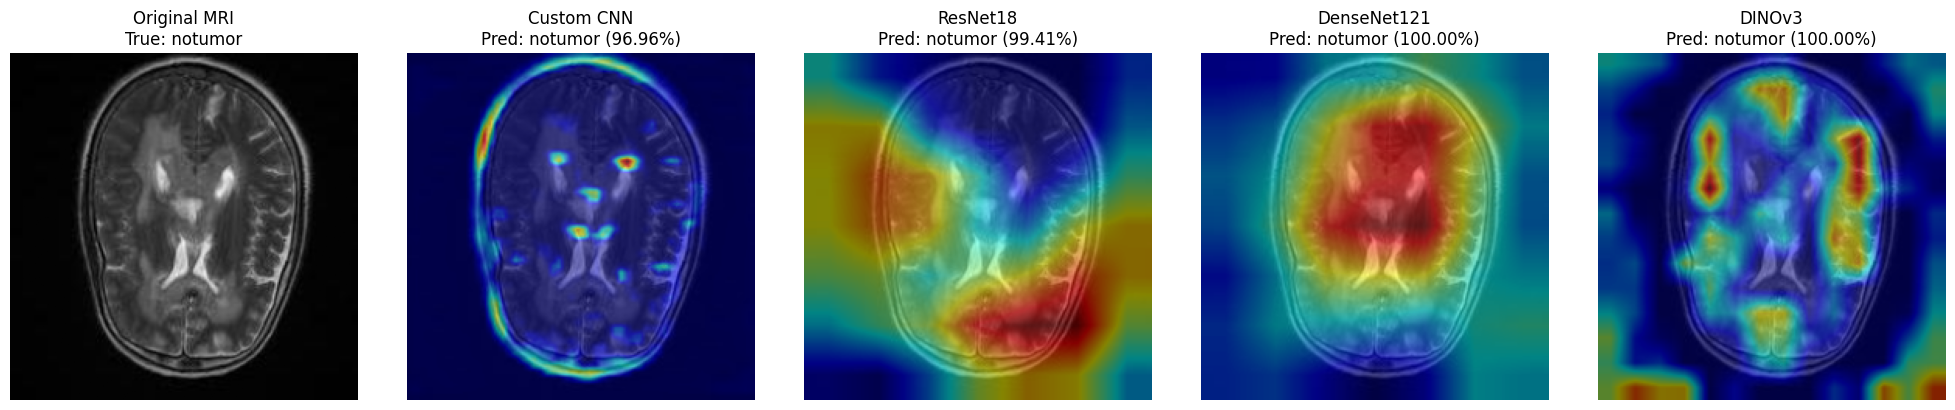


Custom CNN wrong - pretrained models correct
Selected idx: 796


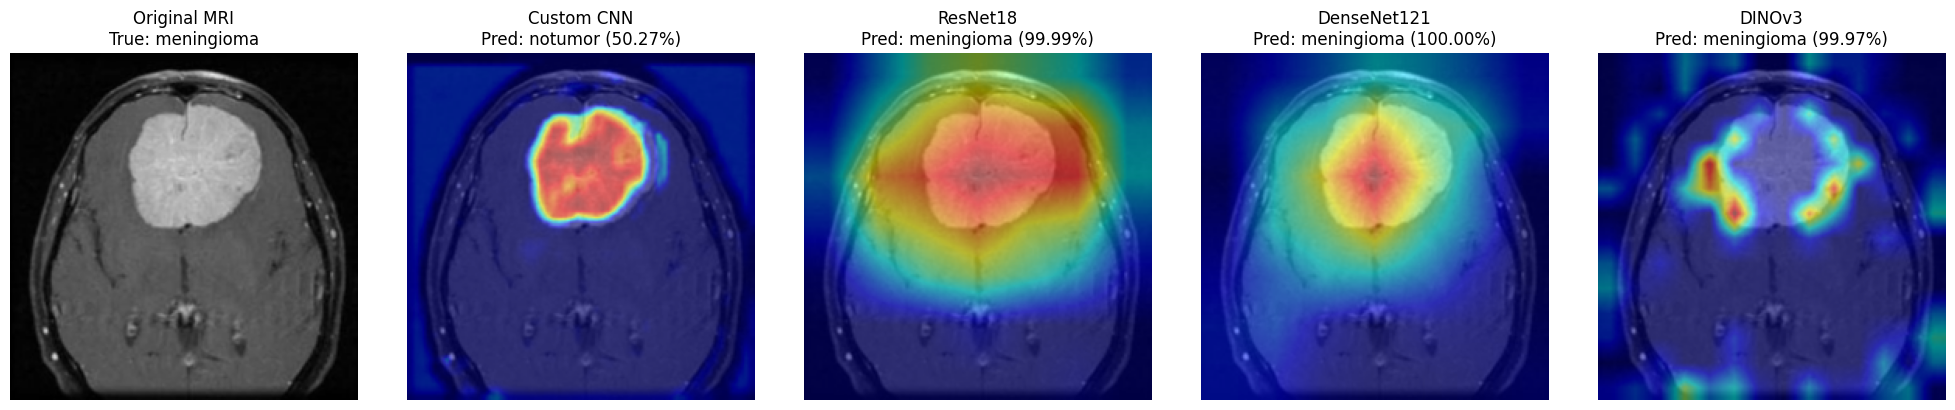


ResNet18 correct - DenseNet121 wrong
Selected idx: 672


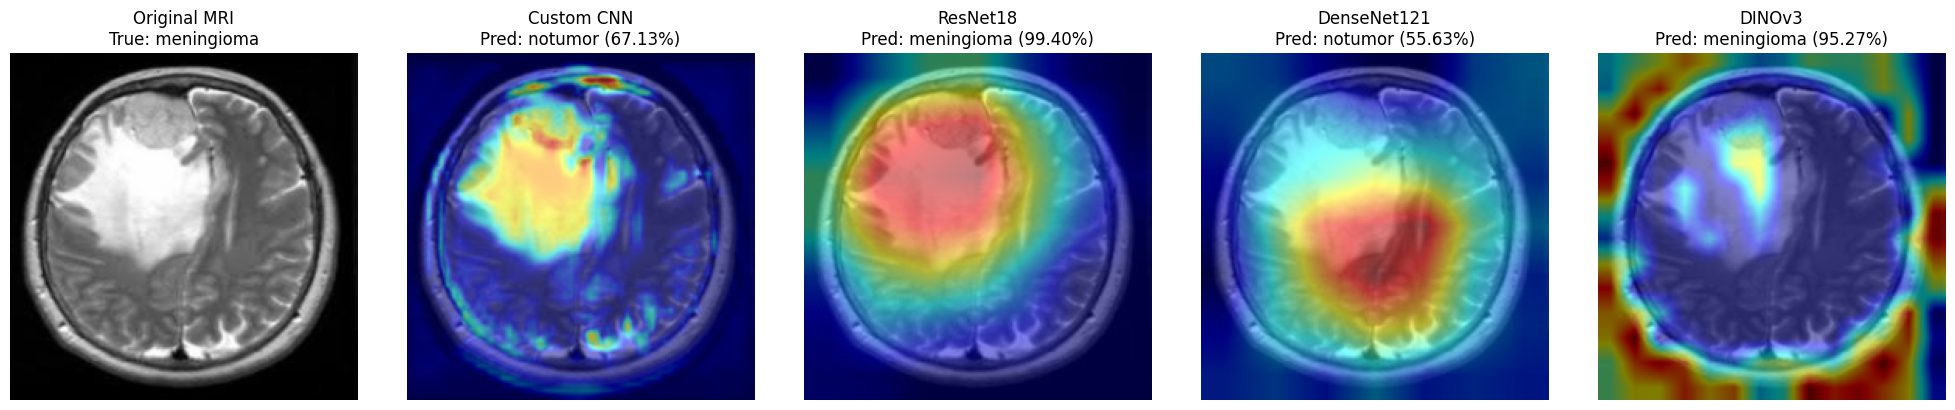


DenseNet121 correct - ResNet18 wrong
Selected idx: 723


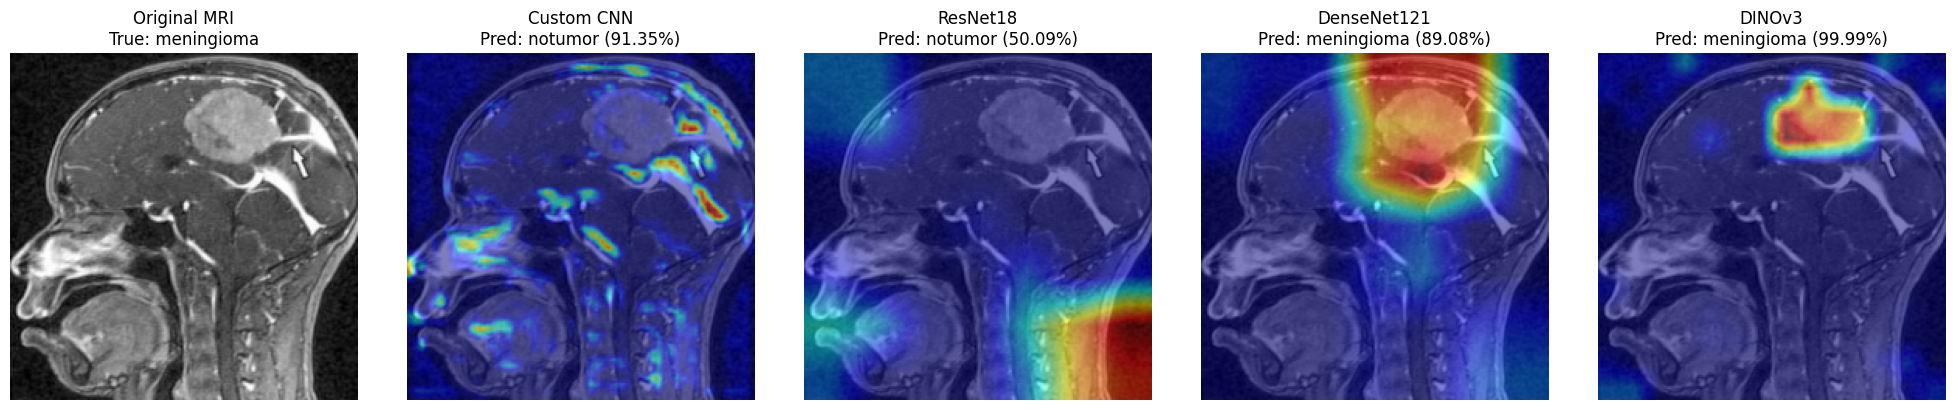


DINOv3 wrong - ResNet18 and DenseNet121 correct
Selected idx: 386


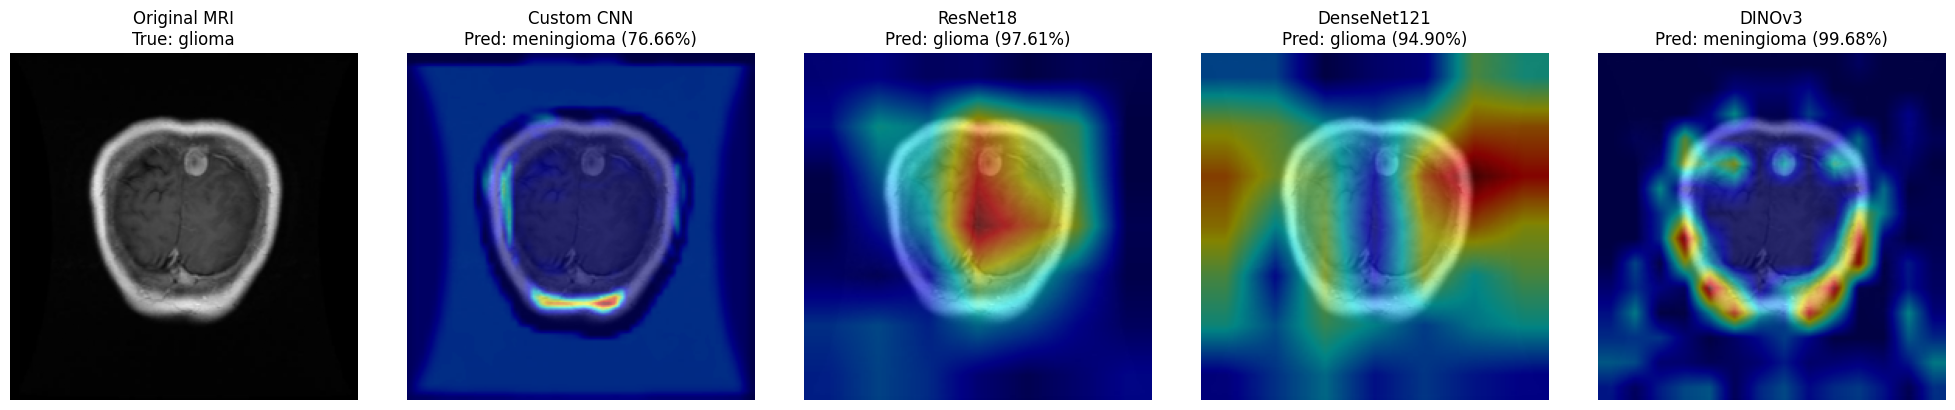

In [89]:
rng = np.random.default_rng(41)

for case_name, indices in cases.items():

    if len(indices) == 0:
        print(f"No samples: {case_name}")
        continue

    # Randomly select one sample
    selected_idx = int(rng.choice(indices))

    print(f"\n{case_name}")
    print(f"Selected idx: {selected_idx}")

    compare_gradcam(idx=selected_idx)

Across the Grad-CAM experiments, comparing spatial activation maps against clinical ground truth reveals critical insights into how different architectures make decisions

- **Custom CNN:** The model frequently focuses on image boundaries rather than tumor regions but can still make correct predictions. Because when trained from scratch on a limited dataset, it may rely on low-level features such as edges, textures, or dataset-specific patterns associated with each class. Interestingly, the model can also highlight the visible tumor region while producing an incorrect prediction. This may indicate that the model responds to visually distinctive features within the lesion but fails to learn sufficiently discriminative representations for accurate classification
- **ResNet-18 & DenseNet-121:** Both models achieve high classification accuracy and confidence, even when their Grad-CAM activations do not precisely align with the tumor. Their high-level features may capture contextual information from surrounding brain structures, while the limited spatial resolution of Grad-CAM can produce broad activation regions. Comparing the two, DenseNet-121 succeeds where ResNet-18 fails on subtle lesions with indistinct boundaries thanks to multi-scale feature reuse across dense blocks, whereas ResNet-18 outperforms DenseNet-121 when prominent surrounding anatomical structures over-activate DenseNet’s concatenated channels.
- **DINOv3 ViT-S/16:** Grad-CAM activations are often scattered across multiple regions, sometimes highlighting the visible tumor and sometimes focusing on surrounding structures. One possible explanation is the Transformer's self-attention mechanism. Unlike CNNs, Vision Transformers integrate information across image patches through self-attention, making spatial attribution more challenging to interpret. Future work could investigate Transformer-specific explainability methods, such as Attention Rollout and Layer-wise Relevance Propagation (LRP), to further analyze DINOv3 predictions.

# Experimental Results

In [51]:
def evaluate_model(model, test_loader, device):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.inference_mode():
        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    
    report = classification_report(
        all_labels,
        all_preds,
        target_names=val_full_resnet.classes,
        zero_division=0,
        output_dict=True
    )

    macro_precision = report["macro avg"]["precision"]
    macro_recall = report["macro avg"]["recall"]
    macro_f1 = report["macro avg"]["f1-score"]
    accuracy = report["accuracy"]
    
    return {
        "accuracy": accuracy,

        "precision": macro_precision,

        "recall": macro_recall,

        "macro_f1": macro_f1,

        "labels": np.array(all_labels),
        "preds": np.array(all_preds)
    }

In [49]:
model_configs = {
    "Custom CNN": {
        "model": custom_cnn,
        "checkpoint": "/kaggle/input/models/onphct/custom-cnn/pytorch/default/1/best_custom_cnn.pth",
        "test_loader": test_loader
    },

    "ResNet18": {
        "model": resnet,
        "checkpoint": "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_layer3.pth",
        "test_loader": test_loader_resnet
    },

    "DenseNet121": {
        "model": densenet,
        "checkpoint": "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_denseblock3.pth",
        "test_loader": test_loader_densenet
    },

    "DINOv3 ViT-S/16": {
        "model": dinov3,
        "checkpoint": "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_last4blocks.pth",
        "test_loader": test_loader_dinov3
    }
}

phase1_configs = {
    "ResNet18": {
        "checkpoint": "/kaggle/input/models/onphct/resnet18/pytorch/default/1/best_resnet18_head.pth",
        "classifier": "fc"
    },

    "DenseNet121": {
        "checkpoint": "/kaggle/input/models/onphct/densenet121/pytorch/default/1/best_densenet121_head.pth",
        "classifier": "classifier"
    },

    "DINOv3 ViT-S/16": {
        "checkpoint": "/kaggle/input/models/onphct/dinov3-weight/pytorch/default/1/best_dinov3_head.pth",
        "classifier": "classifier"
    }
}

In [ ]:
results = []
detailed_results = {}

for name, config in model_configs.items():

    print(f"Evaluating {name}")

    model = config["model"].to(device)

    model.load_state_dict(
        torch.load(
            config["checkpoint"],
            map_location=device,
            weights_only=True
        )
    )

    metrics = evaluate_model(
        model,
        config["test_loader"],
        device
    )

    # store detail results for confusion matrix
    detailed_results[name] = metrics

    # count parameters
    num_params = sum(
        p.numel() for p in model.parameters()
    )

    results.append({
        "Model": name,
        "Test Acc (%)": metrics["accuracy"] * 100,
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "Macro F1": metrics["macro_f1"],
        "Parameters (M)": num_params / 1e6
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

In [83]:
plot_df = results_df.copy()

# Đổi sang % cho đồng nhất khi vẽ
plot_df["Precision (%)"] = plot_df["Precision"] * 100
plot_df["Recall (%)"] = plot_df["Recall"] * 100
plot_df["Macro F1 (%)"] = plot_df["Macro F1"] * 100

# Improvement so với Custom CNN
baseline_acc = plot_df.loc[
    plot_df["Model"] == "Custom CNN",
    "Test Acc (%)"
].iloc[0]

plot_df["Improvement (%)"] = (
    (plot_df["Test Acc (%)"] - baseline_acc) / baseline_acc
) * 100

In [ ]:
# Count params in classifier layer 
def count_params(module):
    return sum(p.numel() for p in module.parameters())


fe_results = []
fe_detailed_results = {}

for name, fe_config in phase1_configs.items():

    print(f"Evaluating {name} - Feature Extraction")

    config = model_configs[name]
    model = config["model"].to(device)

    checkpoint_path = fe_config["checkpoint"]

    if not Path(checkpoint_path).is_file():
        raise FileNotFoundError(checkpoint_path)

    # Load best Phase 1 checkpoint
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    # Classification head
    classifier = getattr(
        model,
        fe_config["classifier"]
    )

    head_params = count_params(classifier)

    # Evaluate on Test set
    metrics = evaluate_model(
        model,
        config["test_loader"],
        device
    )

    fe_detailed_results[name] = metrics

    fe_results.append({
        "Model": name,
        "FE Test Acc (%)": metrics["accuracy"] * 100,
        "FE Macro F1": metrics["macro_f1"],
        "FE Params": head_params,
        "FE Params (M)": head_params / 1e6
    })

fe_results_df = pd.DataFrame(fe_results)

display(fe_results_df.round(6))

In [80]:
# Count trainable parameters in best FT phase
def count_unique_params(modules):
    seen = set()
    total = 0

    for module in modules:
        for p in module.parameters():
            if id(p) not in seen:
                seen.add(id(p))
                total += p.numel()

    return total


ft_trainable_params = {
    "ResNet18": count_unique_params([
        resnet.layer3,
        resnet.layer4,
        resnet.fc
    ]),

    "DenseNet121": count_unique_params([
        densenet.features.denseblock3,
        densenet.features.transition3,
        densenet.features.denseblock4,
        densenet.features.norm5,
        densenet.classifier
    ]),

    "DINOv3 ViT-S/16": count_unique_params([
        dinov3.backbone.layer[-4:],
        dinov3.backbone.norm,
        dinov3.classifier
    ])
}

In [ ]:
ft_df = results_df[
    ["Model", "Test Acc (%)", "Macro F1"]
].rename(columns={
    "Test Acc (%)": "FT Test Acc (%)",
    "Macro F1": "FT Macro F1"
})

comparison_df = fe_results_df.merge(
    ft_df,
    on="Model",
    how="inner",
    validate="one_to_one"
)

comparison_df["FT Params (M)"] = (
    comparison_df["Model"]
    .map(ft_trainable_params) / 1e6
)

comparison_df["Accuracy Gain (pp)"] = (
    comparison_df["FT Test Acc (%)"]
    - comparison_df["FE Test Acc (%)"]
)

comparison_df["FE / FT Accuracy (%)"] = (
    comparison_df["FE Test Acc (%)"]
    / comparison_df["FT Test Acc (%)"]
) * 100

display(comparison_df.round(6))

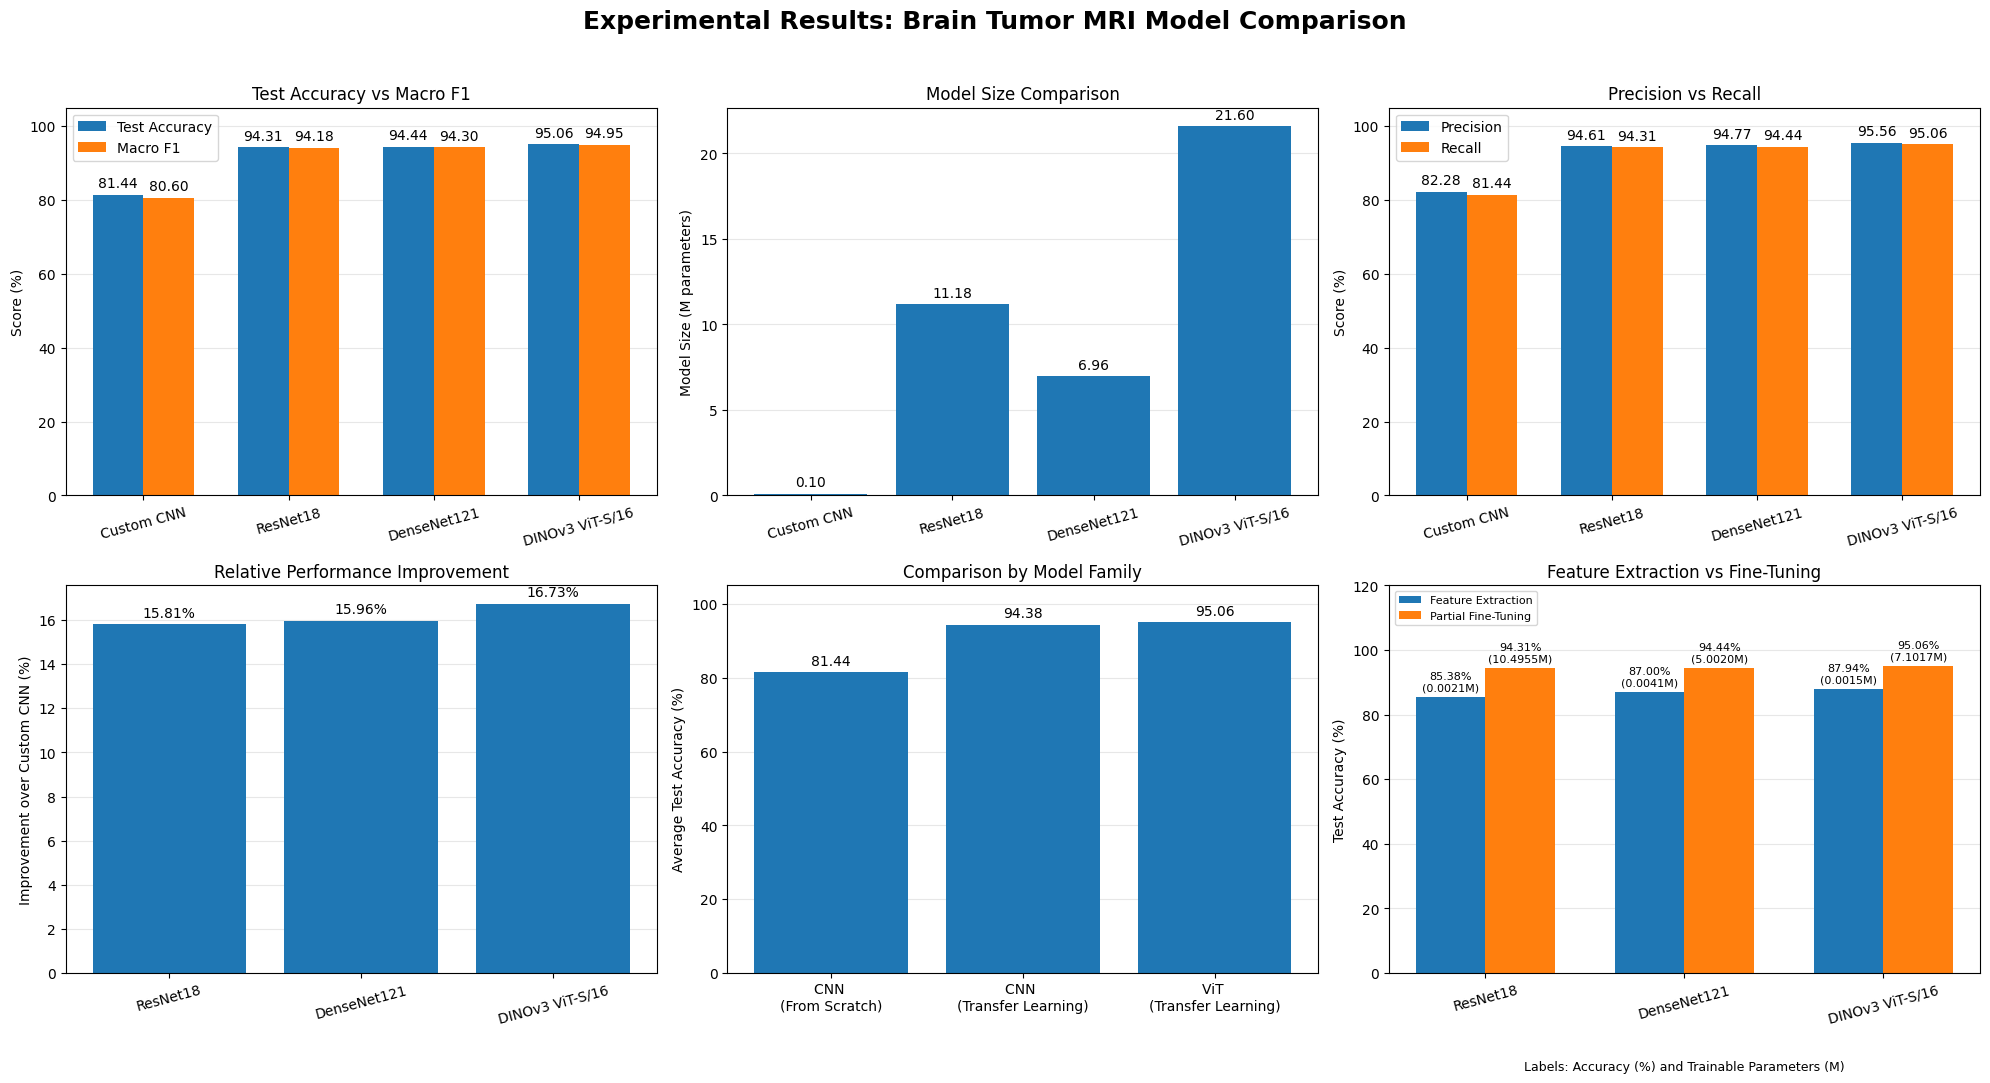

In [84]:
warnings.filterwarnings("ignore", category=UserWarning)

# -----------------------------
# Data
# -----------------------------
models_names = plot_df["Model"]
x = np.arange(len(models_names))

test_acc = plot_df["Test Acc (%)"]
macro_f1 = plot_df["Macro F1 (%)"]
precision = plot_df["Precision (%)"]
recall = plot_df["Recall (%)"]
params = plot_df["Parameters (M)"]
improvement = plot_df["Improvement (%)"]

# -----------------------------
# Group comparison data
# -----------------------------
# Custom CNN = Scratch
scratch_acc = plot_df.loc[
    plot_df["Model"] == "Custom CNN",
    "Test Acc (%)"
].mean()

# Pretrained CNN = ResNet18 + DenseNet121
pretrained_cnn_acc = plot_df.loc[
    plot_df["Model"].isin(["ResNet18", "DenseNet121"]),
    "Test Acc (%)"
].mean()

# Transformer = DINOv3
transformer_acc = plot_df.loc[
    plot_df["Model"] == "DINOv3 ViT-S/16",
    "Test Acc (%)"
].mean()

group_names = ["CNN \n(From Scratch)", "CNN \n(Transfer Learning)", "ViT \n(Transfer Learning)"]
group_values = [scratch_acc, pretrained_cnn_acc, transformer_acc]

# -----------------------------
# Figure
# -----------------------------
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle(
    "Experimental Results: Brain Tumor MRI Model Comparison",
    fontsize=18,
    fontweight="bold"
)

# =======================================
# 1) Test Accuracy vs Macro F1
# =======================================
width = 0.35

bars1 = axes[0, 0].bar(
    x - width / 2,
    test_acc,
    width,
    label="Test Accuracy"
)

bars2 = axes[0, 0].bar(
    x + width / 2,
    macro_f1,
    width,
    label="Macro F1"
)

axes[0, 0].set_title("Test Accuracy vs Macro F1")
axes[0, 0].set_ylabel("Score (%)")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(models_names, rotation=15)
axes[0, 0].set_ylim(0, 105)
axes[0, 0].legend()

axes[0, 0].bar_label(bars1, fmt="%.2f", padding=3)
axes[0, 0].bar_label(bars2, fmt="%.2f", padding=3)

# =======================================
# 2) Model Size Comparison
# =======================================
bars = axes[0, 1].bar(models_names, params)

axes[0, 1].set_title("Model Size Comparison")
axes[0, 1].set_ylabel("Model Size (M parameters)")
axes[0, 1].set_xticklabels(models_names, rotation=15)
axes[0, 1].bar_label(bars, fmt="%.2f", padding=3)

# =======================================
# 3) Precision vs Recall
# =======================================
bars1 = axes[0, 2].bar(
    x - width / 2,
    precision,
    width,
    label="Precision"
)

bars2 = axes[0, 2].bar(
    x + width / 2,
    recall,
    width,
    label="Recall"
)

axes[0, 2].set_title("Precision vs Recall")
axes[0, 2].set_ylabel("Score (%)")
axes[0, 2].set_xticks(x)
axes[0, 2].set_xticklabels(models_names, rotation=15)
axes[0, 2].set_ylim(0, 105)
axes[0, 2].legend()

axes[0, 2].bar_label(bars1, fmt="%.2f", padding=3)
axes[0, 2].bar_label(bars2, fmt="%.2f", padding=3)

# =======================================
# 4) Relative Improvement over Custom CNN
# =======================================
improvement_df = plot_df[
    plot_df["Model"] != "Custom CNN"
].reset_index(drop=True)

x_improvement = np.arange(len(improvement_df))

bars = axes[1, 0].bar(
    x_improvement,
    improvement_df["Improvement (%)"]
)

axes[1, 0].set_title("Relative Performance Improvement")
axes[1, 0].set_ylabel("Improvement over Custom CNN (%)")

axes[1, 0].set_xticks(x_improvement)
axes[1, 0].set_xticklabels(
    improvement_df["Model"],
    rotation=15
)

axes[1, 0].bar_label(bars, fmt="%.2f%%", padding=3)

# =======================================
# 5) Custom CNN vs Pretrained CNN vs Transformer
# =======================================
bars = axes[1, 1].bar(group_names, group_values)

axes[1, 1].set_title("Comparison by Model Family")
axes[1, 1].set_ylabel("Average Test Accuracy (%)")
axes[1, 1].set_ylim(0, 105)
axes[1, 1].bar_label(bars, fmt="%.2f", padding=3)

# =======================================
# 6) Overall Metric Comparison
# =======================================
ax = axes[1, 2]

x_comparison = np.arange(len(comparison_df))
width = 0.35

# Test Accuracy bars
bars_fe = ax.bar(
    x_comparison - width / 2,
    comparison_df["FE Test Acc (%)"],
    width,
    label="Feature Extraction"
)

bars_ft = ax.bar(
    x_comparison + width / 2,
    comparison_df["FT Test Acc (%)"],
    width,
    label="Partial Fine-Tuning"
)

# Labels: Accuracy + Trainable Parameters
fe_labels = [
    f"{acc:.2f}%\n({params:.4f}M)"
    for acc, params in zip(
        comparison_df["FE Test Acc (%)"],
        comparison_df["FE Params (M)"]
    )
]

ft_labels = [
    f"{acc:.2f}%\n({params:.4f}M)"
    for acc, params in zip(
        comparison_df["FT Test Acc (%)"],
        comparison_df["FT Params (M)"]
    )
]

ax.bar_label(
    bars_fe,
    labels=fe_labels,
    padding=3,
    fontsize=8
)

ax.bar_label(
    bars_ft,
    labels=ft_labels,
    padding=3,
    fontsize=8
)

ax.set_title("Feature Extraction vs Fine-Tuning")
ax.set_ylabel("Test Accuracy (%)")

ax.set_xticks(x_comparison)
ax.set_xticklabels(
    comparison_df["Model"],
    rotation=15
)

ax.set_ylim(0, 120)
ax.legend(loc="upper left", fontsize=8)

ax.text(
    0.5, -0.25,
    "Labels: Accuracy (%) and Trainable Parameters (M)",
    transform=ax.transAxes,
    ha="center",
    fontsize=9
)

# ---------------------------------------
# Common styling
# ---------------------------------------
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Analysis and Discussion

## Performance Comparison Across Approaches

**Transfer Learning (Fine-Tuning) Outperforms Training from Scratch:** All three fine-tuned pretrained models outperformed the custom CNN on the brain tumor MRI dataset. While the custom CNN achieved a test accuracy of 81.44%, ResNet-18, DenseNet-121, and DINOv3 ViT-S/16 achieved 94.31%, 94.44%, and 95.06%, respectively.  


**Benefits of Progressive Fine-Tuning:** Fine-tuning deeper layers progressively improved validation accuracy across the pretrained architectures. DenseNet-121 increased from 92.05% with head-only training to **98.66%** after unfreezing additional dense blocks, while DINOv3 improved from 92.23% to **98.66%** after fine-tuning its last four Transformer blocks. ResNet-18 similarly reached from 89.38% to **97.86%** after fine-tuning deeper layers. DINOv3 ViT-S/16 achieved slightly higher head-only accuracy than DenseNet-121 and ResNet-18, potentially reflecting differences between its self-supervised pretraining and the supervised ImageNet pretraining used by the CNNs. However, the difference was small, and additional training across phases may also have contributed to the observed improvements.

**Custom CNN Limitations:** The custom CNN achieved a test accuracy of **81.44%** and a macro F1-score of **0.8060**, which were substantially lower than those of the pretrained models. However, its lightweight architecture contained only approximately 0.10 million parameters, considerably fewer than ResNet-18 (11.18M), DenseNet-121 (6.96M), and DINOv3 (21.60M). Therefore, in specialized applications such as edge computing, IoT devices, and real-time mobile deployment, the custom CNN remains a viable choice due to its minimal memory footprint, low computational overhead, and fast inference speed. Having only 0.10 million parameters severely restricts the model's representational power compared to larger edge architectures (typically 1M–5M parameters), a moderate increase in network capacity could serve as a promising direction for future optimization.


**Architecture Comparison:** In my experiment, ResNet-18 and DenseNet-121 achieved similar test accuracies of **94.31%** and **94.44%** respectively. However, DenseNet121 required approximately 38% fewer parameters than ResNet18. DINOv3 ViT-S/16, a Vision Transformer pretrained through self-supervised learning, achieved the highest test accuracy **(95.06%)** and macro F1-score **(0.9495)**, but contained approximately 3.1 times as many parameters as DenseNet-121. Although DINOv3 performed best on the evaluated test set, its accuracy advantage over DenseNet121 was only 0.63 percentage points. Therefore, these results do not establish that Vision Transformers generally outperform CNNs on medical imaging tasks.

## Trade-offs: Performance vs. Efficiency

**Model Size vs. Accuracy:** Custom CNNs offer the smallest model size but sacrifice accuracy. DINOv3 ViT-S/16 achieves top performance but requires 216× more parameters than custom CNNs, 3× more than DenseNet-121 and 2x more than ResNet-18. For deployment scenarios with strict memory constraints, custom CNNs or DenseNet-121 may be preferable despite slightly lower accuracy.


**Trainable Parameters:** Feature extraction substantially reduces trainable parameters (0.0015–0.0041M vs. 5.00–10.50M for partial fine-tuning), potentially enabling training with more limited computational resources. Despite updating only the classification heads, this approach retained 90.52–92.50% of fine-tuning test accuracy across ResNet18, DenseNet121, and DINOv3, making it a practical alternative when training resources are constrained.

## Practical Recommendations

Based on my experimental findings, I provide the following recommendations:

**Choose Transfer Learning (Partial Fine-Tuning) when:**
- Maximizing classification accuracy is the primary objective
- Sufficient computational resources are available
- Training data is limited and pretrained representations may be beneficial
- The task requires fine-grained discrimination between classes

**Choose Feature Extraction when:**
- Training resources and computational budgets are constrained
- Lower classification accuracy is acceptable for the experimental objective
- Rapid experimentation and model development are priorities
- Minimizing the number of trainable parameters is important

**Choose training from scratch (Custom CNN) when:**
- Model size must be minimized
- Full control over the architecture is required
- Training from scratch and architectural experimentation are primary objectives
- Lower classification accuracy is acceptable for the intended experimental use

**Architecture Selection:** Between the CNN backbones and the Vision Transformer, I recommend DenseNet-121 for storage-constrained deployments due to its compact size (6.96M parameters) and strong performance (94.44% accuracy, 94.30% Macro F1). Note that while DenseNet-121 is smaller in parameter count than ResNet-18 (11.18M), ResNet18 typically offers faster inference throughput and lower runtime memory consumption with negligible accuracy loss (94.31%). DINOv3 ViT-S/16 offers a very minor improvement in accuracy (0.63 percentage points) while while requiring substantially more parameters (21.60M).

## Limitations and Future Work

This experiment has several limitations that suggest directions for future research:

**Dataset Scope:** Our evaluation was limited to a single brain tumor MRI dataset containing four classes. Consequently, the results may not generalize to images from different hospitals, MRI scanners, or acquisition protocols. Future work should evaluate the models on independent external datasets.

**Data Leakage and Generalization:** Although separate training, validation, and test sets were used, patient-level independence and potential image duplication across splits were not verified. Future work should investigate possible data leakage and adopt patient-level splitting where patient identifiers are available.

**Architecture Selection:** We evaluated Custom CNN, ResNet-18, DenseNet-121, and DINOv3 ViT-S/16. Other architectures, such as **EfficientNet, ConvNeXt, VGG-Net, MobileNet varients** may offer different trade-offs between performance and efficiency.

**Hyperparameter Optimization:** Model performance may be influenced by learning rates, augmentation strategies, and fine-tuning configurations. Future work could explore systematic hyperparameter optimization and alternative backbone unfreezing strategies.

**Deployment Considerations:** Our comparison focused on classification performance and parameter counts without benchmarking inference latency, GPU memory consumption, or energy efficiency. Future work should evaluate these metrics to assess practical deployment feasibility.

**Clinical Reliability and Explainability:** Although Grad-CAM was applied to all four models, the resulting heatmaps did not always align with apparent tumor regions, particularly for DINOv3. Without ground-truth tumor annotations, the clinical relevance of these activations remains unverified. Future work should explore Transformer-specific explainability methods, evaluate attribution reliability, and assess model robustness to variations in MRI image quality.

# Conclusion

This study compared a custom CNN trained from scratch with three pretrained architectures—ResNet-18, DenseNet-121, and DINOv3 ViT-S/16—using feature extraction and progressive partial fine-tuning for four-class brain tumor MRI classification. The experimental results demonstrate that transfer learning with partial fine-tuning substantially outperformed both training from scratch (81.44% for the custom CNN) and feature extraction (85.38–87.94%), achieving superior test accuracies of 94.31–95.06%.

Key findings include:

1. **Transfer Learning Effectiveness:** All three fine-tuned pretrained models substantially outperformed the custom CNN, demonstrating the benefits of pretrained representations for this MRI classification task.
2. **Progressive Fine-Tuning:** Partial fine-tuning improved test accuracy by 7.13–8.94 percentage points over head-only feature extraction, highlighting the importance of adapting pretrained features to the target dataset.
3. **Architecture Efficiency:** DINOv3 ViT-S/16 achieved the highest test accuracy (95.06%) and macro F1-score (0.9495), while DenseNet-121 offered a favorable accuracy–model size trade-off, achieving 94.44% accuracy with only 6.96M parameters (~x3 parameters fewer than DINOv3 ViT-S/16)
4. **Model Capacity and Pretraining:** The lightweight custom CNN achieved substantially lower classification accuracy than the evaluated pretrained architectures. However, because the models differ in architecture, parameter count, and pretraining strategy, the individual contributions of these factors cannot be isolated from the current experiments.
5. **Practical trade-offs:** While custom CNN offer advantages in model size (0.1M parameters) and deployment simplicity, these benefits rarely justify the substantial performance sacrifice except in severely resource-constrained scenarios.

For practitioners developing medical image classification systems, our findings support transfer learning with progressive partial fine-tuning as a strong starting point. Although DINOv3 ViT-S/16 achieved the highest test accuracy, its relatively small improvement over DenseNet-121 came with a substantially larger model. Therefore, we recommend DenseNet-121 as a practical choice for balancing classification accuracy and model size, while DINOv3 remains a promising alternative when maximizing predictive performance is the primary objective.

As deep learning architectures continue to evolve, understanding the trade-offs between conventional CNNs and modern Vision Transformers, as well as between different training strategies, remains essential for developing effective and efficient computer vision systems. This study provides empirical evidence and practical guidance for model selection in real-world applications.

# References 

## Research Inspiration

This project was strongly inspired by the comparative experimental framework presented in:

[1] I. Tanvir, A. Ruslan, and S. Solaiman, "Comparative Analysis of Custom CNN Architectures versus Pre-trained Models and Transfer Learning: A Study on Five Bangladesh Datasets," *arXiv preprint arXiv:2601.04352*, 2026.  
**Paper:** https://arxiv.org/abs/2601.04352


## Model Architectures

[2] K. He, X. Zhang, S. Ren, and J. Sun, "Deep Residual Learning for Image Recognition," *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 2016.  
**Paper:** https://arxiv.org/abs/1512.03385

[3] G. Huang, Z. Liu, L. van der Maaten, and K. Q. Weinberger, "Densely Connected Convolutional Networks," *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 2017.  
**Paper:** https://arxiv.org/abs/1608.06993

[4] O. Siméoni et al., "DINOv3," *arXiv preprint arXiv:2508.10104*, 2025.  
**Paper:** https://arxiv.org/abs/2508.10104

[5] R. R. Selvaraju et al., "Grad-CAM: Visual Explanations
from Deep Networks via Gradient-Based Localization,"
*Proceedings of the IEEE International Conference
on Computer Vision (ICCV)*, 2017.
**Paper:** https://arxiv.org/abs/1610.02391